In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 24.4 MB/s eta 0:00:00


In [3]:
import pandas as pd

# Đường dẫn trỏ tới file trong thư mục shortcut của bạn
file_path = '/content/drive/MyDrive/Colab Notebooks/MIMIC_CXR/planB_out/fusion_dataset_hybrid_fullmicro.parquet'

# Thực hiện đọc file vào DataFrame
df = pd.read_parquet(file_path)

# In kích thước
print(f"Kích thước bộ dữ liệu Parquet: {df.shape}")

Kích thước bộ dữ liệu Parquet: (231684, 1537)


In [4]:
from typing import Callable
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.metrics import average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tqdm
import warnings
from imblearn.over_sampling import SMOTENC
from sklearn.impute import KNNImputer
import io
import shutil
warnings.filterwarnings('ignore')

In [5]:
diseases = [
    'dx_pneumonia', 'dx_bronchitis', 'dx_tuberculosis', 'dx_arthritis',
    'dx_fracture', 'dx_scoliosis', 'dx_lung_cancer', 'dx_lung_infection'
]

img_feats = [f'img_{x}' for x in range(768)]

mimic_clinical_feats = [
    'age', 'smoke', 'cough', 'ed_cough', 'gender',
    'vital_heart_rate', 'vital_spo2', 'vital_temperature',
    'vital_resprate', 'vital_sbp', 'vital_dbp',
    'lab_hemoglobin', 'lab_wbc', 'lab_rbc', 'lab_platelet',
    'lab_creatinine', 'lab_sodium', 'lab_potassium', 'lab_glucose',
    'lab_bun', 'lab_chloride',
    'n_positive_cultures'
]

mimic_microbio_feats = [col for col in df.columns if col.startswith('org_') or col.startswith('spec_')]

chexpert_feats = [
    'y_Atelectasis', 'y_Cardiomegaly', 'y_Consolidation', 'y_Edema',
    'y_Enlarged Cardiomediastinum', 'y_Fracture', 'y_Lung Lesion',
    'y_Lung Opacity', 'y_No Finding', 'y_Pleural Effusion',
    'y_Pleural Other', 'y_Pneumonia', 'y_Pneumothorax', 'y_Support Devices'
]

mimic_feats = mimic_clinical_feats + mimic_microbio_feats

models = [
    LGBMClassifier
]
data = df[img_feats + mimic_feats + chexpert_feats].copy()
categorical_cols = ['gender']
for col in categorical_cols:
    if col in data.columns:
        data[col] = data[col].astype('category').cat.codes
for d in diseases:
    df[d] = df[d].astype(int)

In [6]:
data

,img_0,img_1,img_2,img_3,img_4,img_5,img_6,img_7,img_8,img_9,...,y_Enlarged Cardiomediastinum,y_Fracture,y_Lung Lesion,y_Lung Opacity,y_No Finding,y_Pleural Effusion,y_Pleural Other,y_Pneumonia,y_Pneumothorax,y_Support Devices
0,0.089355,0.266682,0.179710,0.876625,-0.029006,0.399481,0.202795,0.192303,-0.101173,0.043450,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-1.224397,0.433193,1.089021,-0.386031,0.336715,-1.302542,0.331434,-0.442539,0.309446,0.726152,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.875164,0.666234,0.883391,-0.184226,-0.197405,-0.370167,0.315198,-0.501882,0.080947,-0.071096,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.262736,0.653497,-0.357070,0.106417,0.221396,1.268205,0.617406,0.245354,0.203167,0.327801,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.141758,-0.097773,1.618124,-1.004805,-0.001702,0.655574,0.597992,-0.524112,0.078801,0.404864,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231679,0.013301,-0.463052,0.309092,0.625109,-0.001932,1.218207,1.115659,0.151097,0.090796,0.171298,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
231680,-0.341683,0.477283,0.667488,0.223247,0.353738,-0.125440,0.127946,0.365124,0.148731,0.202117,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
231681,0.076244,-0.596023,0.124875,0.177235,0.066086,-0.767326,1.131954,0.073524,0.155410,-0.608922,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
231682,0.291791,-1.075142,0.296821,-0.116462,-0.109552,0.039480,-0.843173,-0.807994,0.427896,-0.051257,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
def classify_and_compare(clf: Callable, d, l,
                         test:float = 0.35,
                         verbose:int = 0,
                         print_res:bool = False,
                         df = None,
                         engineering:str = 'None',
                         disease:str = 'None',
                         seed: int = None):
  r'''
  Compare data with and without additional MIMIC-IV Features

  Params
  ---
  - `clf`: The classifier initialization function (sklearn style)
  - `d`: dataset that contains both MIMIC-IV and image data features
  - `l`: label data
  - `test`: test split ratio
  - `verbose`: If you want to print out the progress in the classfier while fitting
  - `print_res`: If result is to be printed or exported to a dataframe column
  - `df`: the dataframe to append results to if not printing
  - `engineering`: Specify if any data engineering is done
  - `disease`: Name of the disease being classified
  '''
  # Split to train and test
  xtr, xte, ytr, yte = train_test_split(d, l, test_size=test, random_state=seed)

  # c1: With all features
  b = clf().fit(xtr,ytr)
  p = b.predict(xte)
  c1 = classification_report(yte, p, output_dict = not print_res)

  # c2: Image features only
  b = clf().fit(xtr[img_feats],ytr)
  p = b.predict(xte[img_feats])
  c2 = classification_report(yte, p, output_dict = not print_res)

  # c3: Original structure: a linear layer with sigmoid activation on image features
  b = LogisticRegression().fit(xtr[img_feats],ytr)
  p = b.predict(xte[img_feats])
  c3 = classification_report(yte, p, output_dict = not print_res)

  # Either print result or append to dataframe
  if print_res:
    print(c1 + '\n' + c2 + '\n' + c3)
  else:
    col = pd.Series({'Model': clf.__name__,
                     'Engineering': engineering,
                     'Disease': disease,
                     # Accuracy
                     'acc_e': c1['accuracy'],
                     'acc_o': c2['accuracy'],
                     'acc_d': c1['accuracy'] - c2['accuracy'],
                     'acc_i': c2['accuracy'] - c3['accuracy'],
                     'acc_x': c1['accuracy'] - c3['accuracy'],
                     # Precision for negative
                     'p0_e': c1['0']['precision'],
                     'p0_o': c2['0']['precision'],
                     'p0_d': c1['0']['precision'] - c2['0']['precision'],
                     # Precision for positive
                     'p1_e': c1['1']['precision'],
                     'p1_o': c2['1']['precision'],
                     'p1_d': c1['1']['precision'] - c2['1']['precision'],
                     'p1_i': c2['1']['precision'] - c3['1']['precision'],
                     'p1_x': c1['1']['precision'] - c3['1']['precision'],
                     # Recall for negative
                     'r0_e': c1['0']['recall'],
                     'r0_o': c2['0']['recall'],
                     'r0_d': c1['0']['recall'] - c2['0']['recall'],
                     # Recall for positive
                     'r1_e': c1['1']['recall'],
                     'r1_o': c2['1']['recall'],
                     'r1_d': c1['1']['recall'] - c2['1']['recall'],
                     # F1-score negative
                     'f1_0_e': c1['0']['f1-score'],
                     'f1_0_o': c2['0']['f1-score'],
                     # F1-score positive
                     'f1_1_e': c1['1']['f1-score'],
                     'f1_1_o': c2['1']['f1-score'],
                     })
    df[len(df.columns)] = col

In [8]:
base_seed = 42
# Number of times run per model
n_iter = 5
# Desired test size
test_size = 0.35
res_default = pd.DataFrame()

# For each group of disease and model, perform n comparison runs
for d in tqdm.tqdm(diseases):
  l = df[d]
  for m in models:
    for i in range(n_iter):
      classify_and_compare(m, data, l, test_size, df=res_default, engineering='None', disease=d, seed=base_seed + i)

res_default.T

  0%|          | 0/8 [00:00<?, ?it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 101082, number of negative: 49512
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.035941 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 200727
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 1212
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.671222 -> initscore=0.713717
[LightGBM] [Info] Start training from score 0.713717
[LightGBM] [Info] Number of positive: 101082, number of negative: 49512
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.645153 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195840
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 768
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.671222 

 12%|█▎        | 1/8 [05:44<40:13, 344.82s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 20136, number of negative: 130458
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.982195 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 200727
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 1212
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.133711 -> initscore=-1.868542
[LightGBM] [Info] Start training from score -1.868542
[LightGBM] [Info] Number of positive: 20136, number of negative: 130458
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.627509 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195840
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 768
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.13371

 25%|██▌       | 2/8 [11:37<34:56, 349.47s/it]

...

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 23239, number of negative: 127355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.806445 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 200727
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 1212
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.154316 -> initscore=-1.701147
[LightGBM] [Info] Start training from score -1.701147
[LightGBM] [Info] Number of positive: 23239, number of negative: 127355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.524141 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195840
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 768
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.15431

 88%|████████▊ | 7/8 [37:55<05:18, 318.00s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 25854, number of negative: 124740
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.386247 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 200727
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 1212
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.171680 -> initscore=-1.573766
[LightGBM] [Info] Start training from score -1.573766
[LightGBM] [Info] Number of positive: 25854, number of negative: 124740
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.964287 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195840
[LightGBM] [Info] Number of data points in the train set: 150594, number of used features: 768
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.17168

100%|██████████| 8/8 [43:07<00:00, 323.46s/it]


,Model,Engineering,Disease,acc_e,acc_o,acc_d,acc_i,acc_x,p0_e,p0_o,...,r0_e,r0_o,r0_d,r1_e,r1_o,r1_d,f1_0_e,f1_0_o,f1_1_e,f1_1_o
0,LGBMClassifier,None,dx_pneumonia,0.822802,0.68657,0.136231,-0.002762,0.133469,0.752111,0.572852,...,0.689847,0.193551,0.496297,0.888186,0.929026,-0.04084,0.719635,0.289341,0.870467,0.79895
1,LGBMClassifier,None,dx_pneumonia,0.822974,0.690245,0.132729,-0.001036,0.131693,0.75001,0.589752,...,0.69346,0.194434,0.499026,0.886546,0.933612,-0.047066,0.720627,0.292451,0.870439,0.801721
2,LGBMClassifier,None,dx_pneumonia,0.8248,0.689419,0.13538,-0.000691,0.13469,0.751324,0.574697,...,0.694684,0.196813,0.497871,0.888115,0.929125,-0.041011,0.721895,0.293211,0.872118,0.800983
3,LGBMClassifier,None,dx_pneumonia,0.824812,0.690282,0.13453,-0.000814,0.133716,0.75375,0.587462,...,0.69375,0.194388,0.499362,0.888999,0.933146,-0.044147,0.722507,0.292116,0.872002,0.801777
4,LGBMClassifier,None,dx_pneumonia,0.823653,0.688704,0.134949,-0.002491,0.132458,0.755368,0.585172,...,0.688082,0.192439,0.495643,0.890357,0.932878,-0.042521,0.720157,0.28963,0.871264,0.800679
5,LGBMClassifier,None,dx_bronchitis,0.917524,0.868874,0.04865,0.001246,0.049895,0.916742,0.869754,...,0.995144,0.998049,-0.002905,0.415723,0.033784,0.381939,0.954336,0.929495,0.574555,0.064573
6,LGBMClassifier,None,dx_bronchitis,0.917043,0.868627,0.048415,0.001024,0.049439,0.916449,0.869521,...,0.994857,0.997977,-0.00312,0.41607,0.035865,0.380205,0.954045,0.929331,0.574214,0.068387
7,LGBMClassifier,None,dx_bronchitis,0.916291,0.868603,0.047688,0.001406,0.049094,0.915702,0.869335,...,0.994841,0.998176,-0.003335,0.411754,0.036342,0.375412,0.953633,0.929311,0.569944,0.069351
8,LGBMClassifier,None,dx_bronchitis,0.916044,0.868147,0.047897,0.000876,0.048773,0.915777,0.869131,...,0.994397,0.997819,-0.003421,0.413888,0.037095,0.376793,0.953469,0.92904,0.57096,0.070584
9,LGBMClassifier,None,dx_bronchitis,0.917302,0.868985,0.048317,0.001776,0.050092,0.916818,0.869717,...,0.9947,0.998148,-0.003448,0.419219,0.037777,0.381441,0.954172,0.929517,0.576909,0.071978


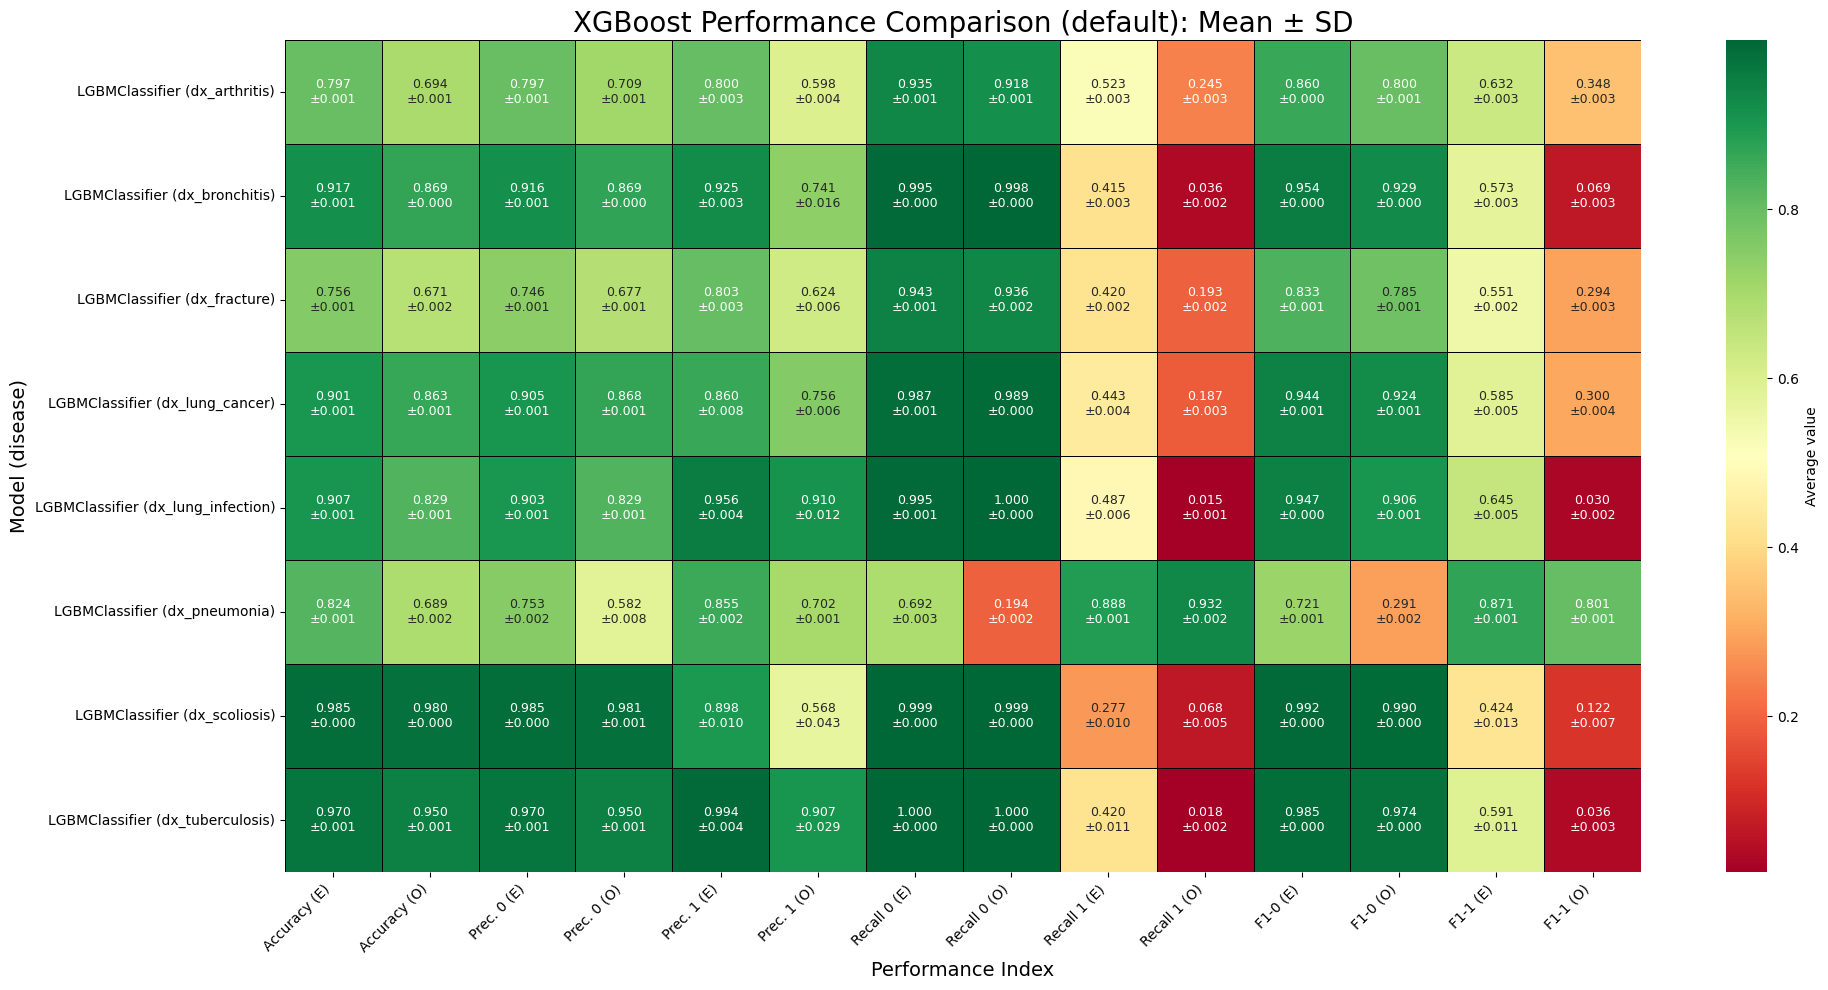

In [9]:
#default
import io

res_default_T = res_default.T
csv_string = res_default_T.to_csv(index=True)
df_data = pd.read_csv(io.StringIO(csv_string))

metrics_to_plot = [
    'acc_e', 'acc_o',
    'p0_e', 'p0_o',
    'p1_e', 'p1_o',
    'r0_e', 'r0_o',
    'r1_e', 'r1_o',
    'f1_0_e', 'f1_0_o',
    'f1_1_e', 'f1_1_o',
]

new_col_names = {
    'acc_e': 'Accuracy (E)', 'acc_o': 'Accuracy (O)',
    'p0_e': 'Prec. 0 (E)', 'p0_o': 'Prec. 0 (O)',
    'p1_e': 'Prec. 1 (E)', 'p1_o': 'Prec. 1 (O)',
    'r0_e': 'Recall 0 (E)', 'r0_o': 'Recall 0 (O)',
    'r1_e': 'Recall 1 (E)', 'r1_o': 'Recall 1 (O)',
    'f1_0_e': 'F1-0 (E)', 'f1_0_o': 'F1-0 (O)',
    'f1_1_e': 'F1-1 (E)', 'f1_1_o': 'F1-1 (O)',
}

grouped = df_data.groupby(['Model', 'Disease'])[metrics_to_plot]
mean_df = grouped.mean()
std_df = grouped.std()

new_index = [f"{m} ({d})" for m, d in mean_df.index]
mean_df.index = new_index
std_df.index = new_index

mean_df = mean_df.rename(columns=new_col_names)
std_df = std_df.rename(columns=new_col_names)

annot_df = mean_df.copy().astype(str)
for col in mean_df.columns:
    annot_df[col] = mean_df[col].map('{:.3f}'.format) + "\n±" + std_df[col].map('{:.3f}'.format)

plt.figure(figsize=(20, 10))

sns.heatmap(
    mean_df,
    annot=annot_df,
    fmt="",
    cmap='RdYlGn',
    linewidths=.5,
    linecolor='black',
    annot_kws={"size": 9},
    cbar_kws={'label': 'Average value'}
)

plt.title('XGBoost Performance Comparison (default): Mean ± SD', fontsize=20)
plt.ylabel('Model (disease)', fontsize=14)
plt.xlabel('Performance Index', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()